<a href="https://colab.research.google.com/github/SabrinaIslamTesa/CVPR/blob/main/Assignments/Mid-Term/CNN_23-53821-3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [6]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
import torchvision.transforms as transforms
from torch.utils.data import random_split

size = 32
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    transforms.RandomRotation(15),        # rotate ±15 degrees
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()                # convert PIL → float tensor [0.0,1.0]
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Load medicinal plant dataset from Google Drive

dataset_path = "/content/drive/MyDrive/CVPR/Datasets/Medicinal_Plant_Assignment_Dataset"

full_dataset = datasets.ImageFolder(
    dataset_path,
    transform=train_transform
)

# Split dataset into train (80%), validation (10%) and test (10%)

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

train_data, val_data, test_data = random_split(
    full_dataset,
    [train_size, val_size, test_size]
)

In [9]:
# Check dataset sizes

print("Train Data:", len(train_data))
print("Validation Data:", len(val_data))
print("Test Data:", len(test_data))

Train Data: 736
Validation Data: 92
Test Data: 92


In [10]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))

# Display class names and class indices
print('Classes and Indices:', full_dataset.class_to_idx)

Dataset Summary
Train Data:  736
Validation Data:  92
Test Data:  92
Classes and Indices: {'Aloevera': 0, 'Amla': 1, 'Curry_Leaf': 2, 'Hibiscus': 3, 'Mint': 4, 'Neem': 5}


In [11]:
batch_size = 32
learning_rate=1e-3
epoch_number = 10

In [12]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [13]:
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 6)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [14]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [15]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 6]           1,542
Total params: 1,257,094
Trainable params: 1,257,094
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.80
Estimat

In [16]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 1.6544 | Train Accuracy: 31.11% | Val Loss: 1.3177 | Val Accuracy: 44.57%
Epoch [2/10] | Train Loss: 1.3539 | Train Accuracy: 42.39% | Val Loss: 1.2889 | Val Accuracy: 43.48%
Epoch [3/10] | Train Loss: 1.2404 | Train Accuracy: 49.73% | Val Loss: 1.2082 | Val Accuracy: 46.74%
Epoch [4/10] | Train Loss: 1.0359 | Train Accuracy: 59.24% | Val Loss: 1.0591 | Val Accuracy: 54.35%
Epoch [5/10] | Train Loss: 0.9336 | Train Accuracy: 63.45% | Val Loss: 1.0367 | Val Accuracy: 54.35%
Epoch [6/10] | Train Loss: 0.8198 | Train Accuracy: 69.29% | Val Loss: 0.9851 | Val Accuracy: 55.43%
Epoch [7/10] | Train Loss: 0.7527 | Train Accuracy: 72.96% | Val Loss: 0.8933 | Val Accuracy: 63.04%
Epoch [8/10] | Train Loss: 0.7223 | Train Accuracy: 71.60% | Val Loss: 0.8687 | Val Accuracy: 66.30%
Epoch [9/10] | Train Loss: 0.6282 | Train Accuracy: 74.59% | Val Loss: 0.9199 | Val Accuracy: 65.22%
Epoch [10/10] | Train Loss: 0.5589 | Train Accuracy: 79.08% | Val Loss: 0.8920 | Val Accura

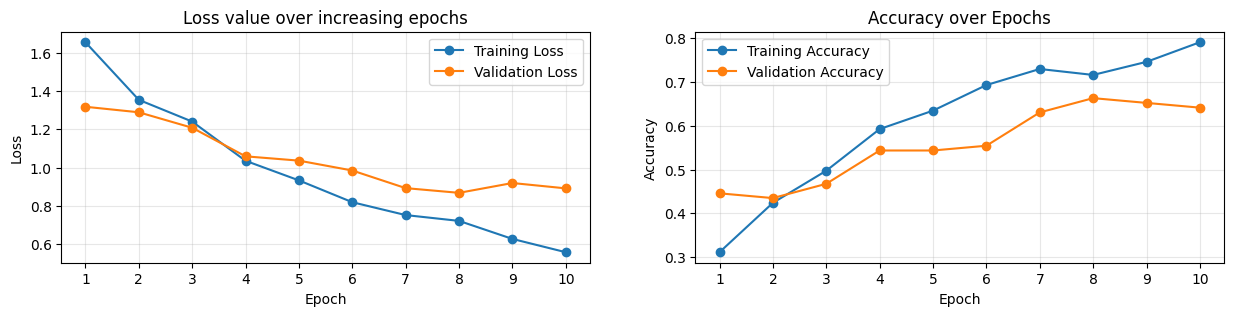

In [17]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

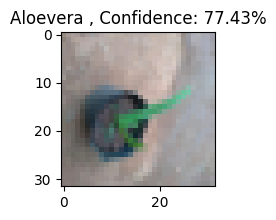

In [18]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f'{full_dataset.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

In [19]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.80 , Test Accuracy: 67.39%


In [20]:
# Save trained CNN model
torch.save(
    model.state_dict(),
    "medicinal_plant_cnn_model.pth"
)

print("Model saved successfully")

Model saved successfully


# Analysis and Discussion

The model was trained on a medicinal plant dataset with six classes.

Training loss decreased during training, while training accuracy improved gradually.

Validation accuracy also increased, which indicates that the model learned meaningful features from the images.

The final test accuracy was 67.39%.

Some classes may be difficult to distinguish because plant leaves can have similar shapes and textures.

# Conclusion

A custom CNN model was developed for medicinal plant classification.

The model achieved 67.39% test accuracy on the test dataset.

The model was able to classify six medicinal plant classes with reasonable performance.

In the future, more images and additional training epochs may improve accuracy.